In [9]:
print("=" * 60)
print("VEIL - AI-POWERED PHISHING URL DETECTION")
print("=" * 60)

VEIL - AI-POWERED PHISHING URL DETECTION


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("VEIL libraries loaded successfully!")

VEIL libraries loaded successfully!


In [51]:
df = pd.read_excel("../data/VEIL_URL_dataset.xlsx")

print("VEIL dataset loaded successfully!")

VEIL dataset loaded successfully!


In [52]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 11430
Number of columns: 55


In [53]:
df.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,6,5.750000,7.0,4.500000,0,0,0,0,0,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,32,15.750000,19.0,14.666667,0,0,0,0,0,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,17,8.250000,8.4,8.142857,0,0,0,0,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,0,5.000000,5.0,0.000000,0,0,0,0,0,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,11,6.333333,5.0,7.000000,0,0,0,0,0,legitimate


In [54]:
print("VEIL DATASET COLUMNS")
print("=" * 50)

print(df.columns)

VEIL DATASET COLUMNS
Index(['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens',
       'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore',
       'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma',
       'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com',
       'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url',
       'ratio_digits_host', 'punycode', 'port', 'tld_in_path',
       'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains',
       'prefix_suffix', 'random_domain', 'shortening_service',
       'path_extension', 'length_words_raw', 'char_repeat',
       'shortest_words_raw', 'shortest_word_host', 'shortest_word_path',
       'longest_words_raw', 'longest_word_host', 'longest_word_path',
       'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints',
       'domain_in_brand', 'brand_in_subdomain', 'brand_in_path',
       'suspecious_tld', 'status'],
      dtype='object')


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 55 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   url                 11430 non-null  object 
 1   length_url          11430 non-null  int64  
 2   length_hostname     11430 non-null  int64  
 3   ip                  11430 non-null  int64  
 4   nb_dots             11430 non-null  int64  
 5   nb_hyphens          11430 non-null  int64  
 6   nb_at               11430 non-null  int64  
 7   nb_qm               11430 non-null  int64  
 8   nb_and              11430 non-null  int64  
 9   nb_or               11430 non-null  int64  
 10  nb_eq               11430 non-null  int64  
 11  nb_underscore       11430 non-null  int64  
 12  nb_tilde            11430 non-null  int64  
 13  nb_percent          11430 non-null  int64  
 14  nb_slash            11430 non-null  int64  
 15  nb_star             11430 non-null  int64  
 16  nb_c

In [56]:
print("DATA TYPES")
print("=" * 50)

print(df.dtypes)

DATA TYPES
url                    object
length_url              int64
length_hostname         int64
ip                      int64
nb_dots                 int64
nb_hyphens              int64
nb_at                   int64
nb_qm                   int64
nb_and                  int64
nb_or                   int64
nb_eq                   int64
nb_underscore           int64
nb_tilde                int64
nb_percent              int64
nb_slash                int64
nb_star                 int64
nb_colon                int64
nb_comma                int64
nb_semicolumn           int64
nb_dollar               int64
nb_space                int64
nb_www                  int64
nb_com                  int64
nb_dslash               int64
http_in_path            int64
https_token             int64
ratio_digits_url      float64
ratio_digits_host     float64
punycode                int64
port                    int64
tld_in_path             int64
tld_in_subdomain        int64
abnormal_subdomain      int64

In [57]:
print("MISSING VALUES")
print("=" * 50)

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

MISSING VALUES
Series([], dtype: int64)


In [58]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [59]:
print("TARGET COLUMN: status")
print("=" * 50)

print("Unique values:")
print(df["status"].unique())

print("\nNumber of samples in each class:")
print(df["status"].value_counts())

TARGET COLUMN: status
Unique values:
['legitimate' 'phishing']

Number of samples in each class:
status
legitimate    5715
phishing      5715
Name: count, dtype: int64


## Matplotlib

Matplotlib is a Python data visualization library used to create graphs and charts.

In this project, Matplotlib is used to visualize the dataset and understand patterns in legitimate and phishing URLs.

It helps us present data in a clear and understandable graphical format.

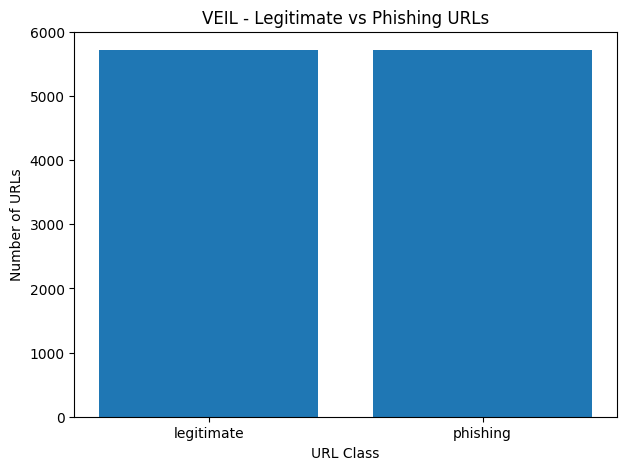

In [60]:
import matplotlib.pyplot as plt

status_counts = df["status"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    status_counts.index,
    status_counts.values
)

plt.title("VEIL - Legitimate vs Phishing URLs")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")

plt.show()

## Seaborn

Seaborn is a Python data visualization library built on Matplotlib.

In this project, Seaborn is used to create statistical visualizations such as countplots, boxplots, and correlation heatmaps.

These visualizations help us understand the distribution of URL features and identify relationships between numerical features.

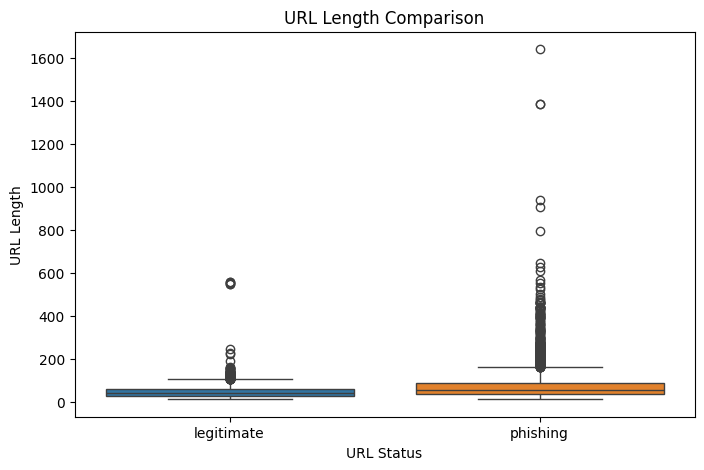

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="status",
    y="length_url",
    hue="status",
    legend=False
)

plt.title("URL Length Comparison")
plt.xlabel("URL Status")
plt.ylabel("URL Length")

plt.show()

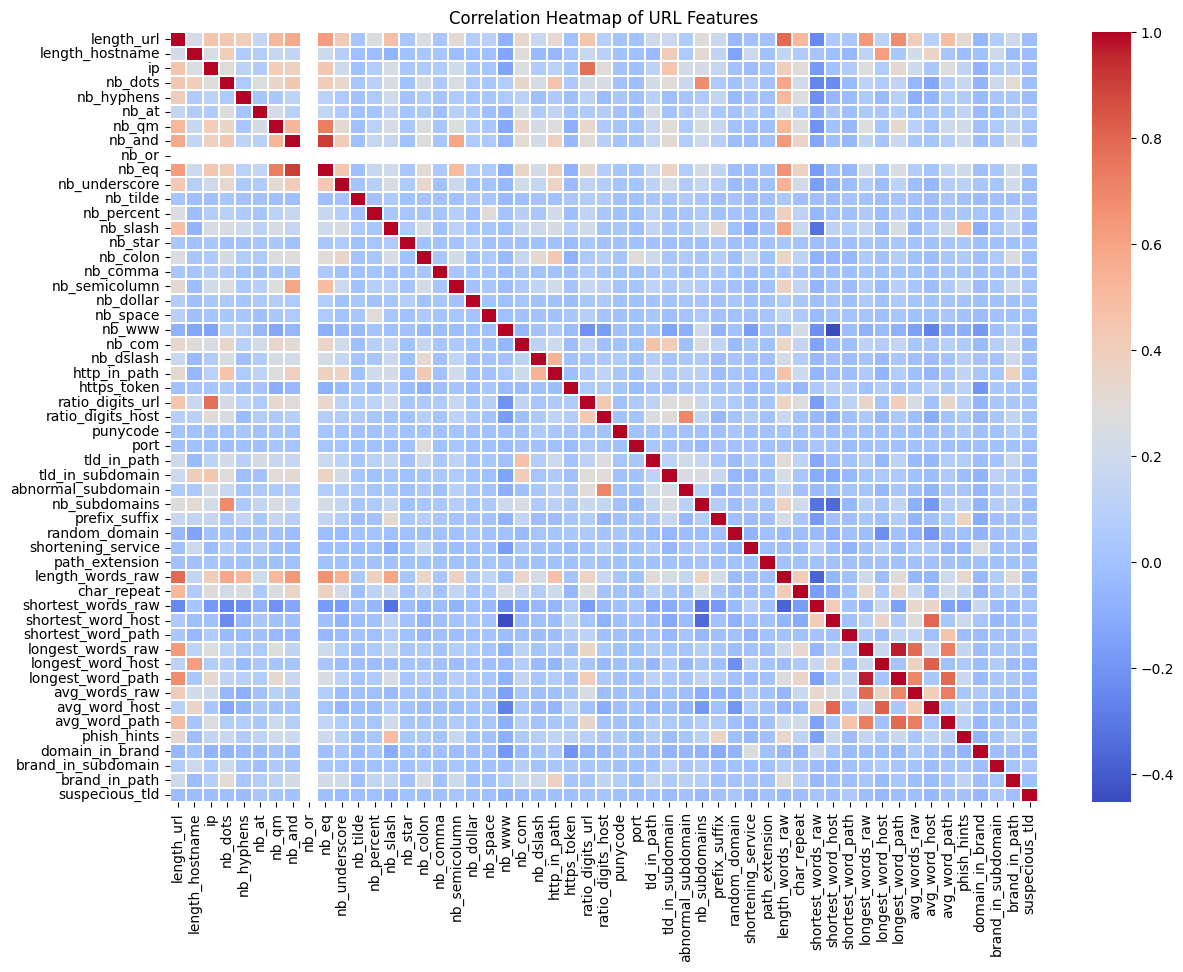

In [28]:
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap of URL Features")

plt.show()

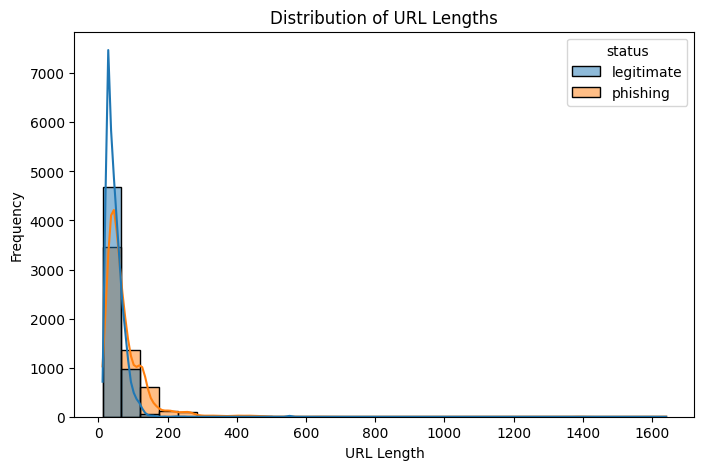

In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="length_url",
    hue="status",
    bins=30,
    kde=True
)

plt.title("Distribution of URL Lengths")
plt.xlabel("URL Length")
plt.ylabel("Frequency")

plt.show()

In [30]:
class_percentages = df["status"].value_counts(normalize=True) * 100

print("CLASS DISTRIBUTION")
print("=" * 50)

for class_name, percentage in class_percentages.items():
    print(f"{class_name}: {percentage:.2f}%")

CLASS DISTRIBUTION
legitimate: 50.00%
phishing: 50.00%


In [31]:
numeric_columns = df.select_dtypes(include=["number"]).columns

print("NUMBER OF NUMERICAL COLUMNS:", len(numeric_columns))
print("=" * 50)

for number, column in enumerate(numeric_columns, start=1):
    print(f"{number:02d}. {column}")

NUMBER OF NUMERICAL COLUMNS: 53
01. length_url
02. length_hostname
03. ip
04. nb_dots
05. nb_hyphens
06. nb_at
07. nb_qm
08. nb_and
09. nb_or
10. nb_eq
11. nb_underscore
12. nb_tilde
13. nb_percent
14. nb_slash
15. nb_star
16. nb_colon
17. nb_comma
18. nb_semicolumn
19. nb_dollar
20. nb_space
21. nb_www
22. nb_com
23. nb_dslash
24. http_in_path
25. https_token
26. ratio_digits_url
27. ratio_digits_host
28. punycode
29. port
30. tld_in_path
31. tld_in_subdomain
32. abnormal_subdomain
33. nb_subdomains
34. prefix_suffix
35. random_domain
36. shortening_service
37. path_extension
38. length_words_raw
39. char_repeat
40. shortest_words_raw
41. shortest_word_host
42. shortest_word_path
43. longest_words_raw
44. longest_word_host
45. longest_word_path
46. avg_words_raw
47. avg_word_host
48. avg_word_path
49. phish_hints
50. domain_in_brand
51. brand_in_subdomain
52. brand_in_path
53. suspecious_tld


In [32]:
numeric_summary = df[numeric_columns].describe().T

numeric_summary

,count,mean,std,min,25%,50%,75%,max
length_url,11430.0,61.126684,55.297318,12.0,33.00,47.000000,71.000000,1641.000000
length_hostname,11430.0,21.090289,10.777171,4.0,15.00,19.000000,24.000000,214.000000
ip,11430.0,0.150569,0.357644,0.0,0.00,0.000000,0.000000,1.000000
nb_dots,11430.0,2.480752,1.369686,1.0,2.00,2.000000,3.000000,24.000000
nb_hyphens,11430.0,0.997550,2.087087,0.0,0.00,0.000000,1.000000,43.000000
nb_at,11430.0,0.022222,0.155500,0.0,0.00,0.000000,0.000000,4.000000
nb_qm,11430.0,0.141207,0.364456,0.0,0.00,0.000000,0.000000,3.000000
nb_and,11430.0,0.162292,0.821337,0.0,0.00,0.000000,0.000000,19.000000
nb_or,11430.0,0.000000,0.000000,0.0,0.00,0.000000,0.000000,0.000000
nb_eq,11430.0,0.293176,0.998317,0.0,0.00,0.000000,0.000000,19.000000


In [33]:
constant_features = []

for column in numeric_columns:
    if df[column].nunique() <= 1:
        constant_features.append(column)

print("CONSTANT FEATURES")
print("=" * 50)

if constant_features:
    for feature in constant_features:
        print(feature)
else:
    print("No constant features found.")

CONSTANT FEATURES
nb_or


In [34]:
df = df.drop(columns=["nb_or"])

print("Removed constant feature: nb_or")
print("New number of columns:", df.shape[1])

Removed constant feature: nb_or
New number of columns: 54


In [35]:
duplicate_count = df.duplicated().sum()

print("DUPLICATE ROW CHECK")
print("=" * 50)
print("Number of duplicate rows:", duplicate_count)

DUPLICATE ROW CHECK
Number of duplicate rows: 0


In [36]:
url_duplicate_count = df["url"].duplicated().sum()

print("DUPLICATE URL CHECK")
print("=" * 50)
print("Number of repeated URLs:", url_duplicate_count)

DUPLICATE URL CHECK
Number of repeated URLs: 1


In [37]:
duplicate_urls = df[df["url"].duplicated(keep=False)].sort_values("url")

duplicate_urls[["url", "status"]]

,url,status
6035,http://e710z0ear.du.r.appspot.com/c:/users/use...,phishing
11305,http://e710z0ear.du.r.appspot.com/c:/users/use...,phishing


In [38]:
df = df.drop_duplicates(subset=["url"], keep="first").reset_index(drop=True)

print("Duplicate URLs removed.")
print("New dataset shape:", df.shape)

Duplicate URLs removed.
New dataset shape: (11429, 54)


In [39]:
X = df.drop(columns=["url", "status"])
y = df["status"]

print("FEATURE DATA (X):", X.shape)
print("TARGET DATA (y):", y.shape)

FEATURE DATA (X): (11429, 52)
TARGET DATA (y): (11429,)


In [40]:
print("VEIL ML FEATURES")
print("=" * 60)

for number, feature in enumerate(X.columns, start=1):
    print(f"{number:02d}. {feature}")

VEIL ML FEATURES
01. length_url
02. length_hostname
03. ip
04. nb_dots
05. nb_hyphens
06. nb_at
07. nb_qm
08. nb_and
09. nb_eq
10. nb_underscore
11. nb_tilde
12. nb_percent
13. nb_slash
14. nb_star
15. nb_colon
16. nb_comma
17. nb_semicolumn
18. nb_dollar
19. nb_space
20. nb_www
21. nb_com
22. nb_dslash
23. http_in_path
24. https_token
25. ratio_digits_url
26. ratio_digits_host
27. punycode
28. port
29. tld_in_path
30. tld_in_subdomain
31. abnormal_subdomain
32. nb_subdomains
33. prefix_suffix
34. random_domain
35. shortening_service
36. path_extension
37. length_words_raw
38. char_repeat
39. shortest_words_raw
40. shortest_word_host
41. shortest_word_path
42. longest_words_raw
43. longest_word_host
44. longest_word_path
45. avg_words_raw
46. avg_word_host
47. avg_word_path
48. phish_hints
49. domain_in_brand
50. brand_in_subdomain
51. brand_in_path
52. suspecious_tld


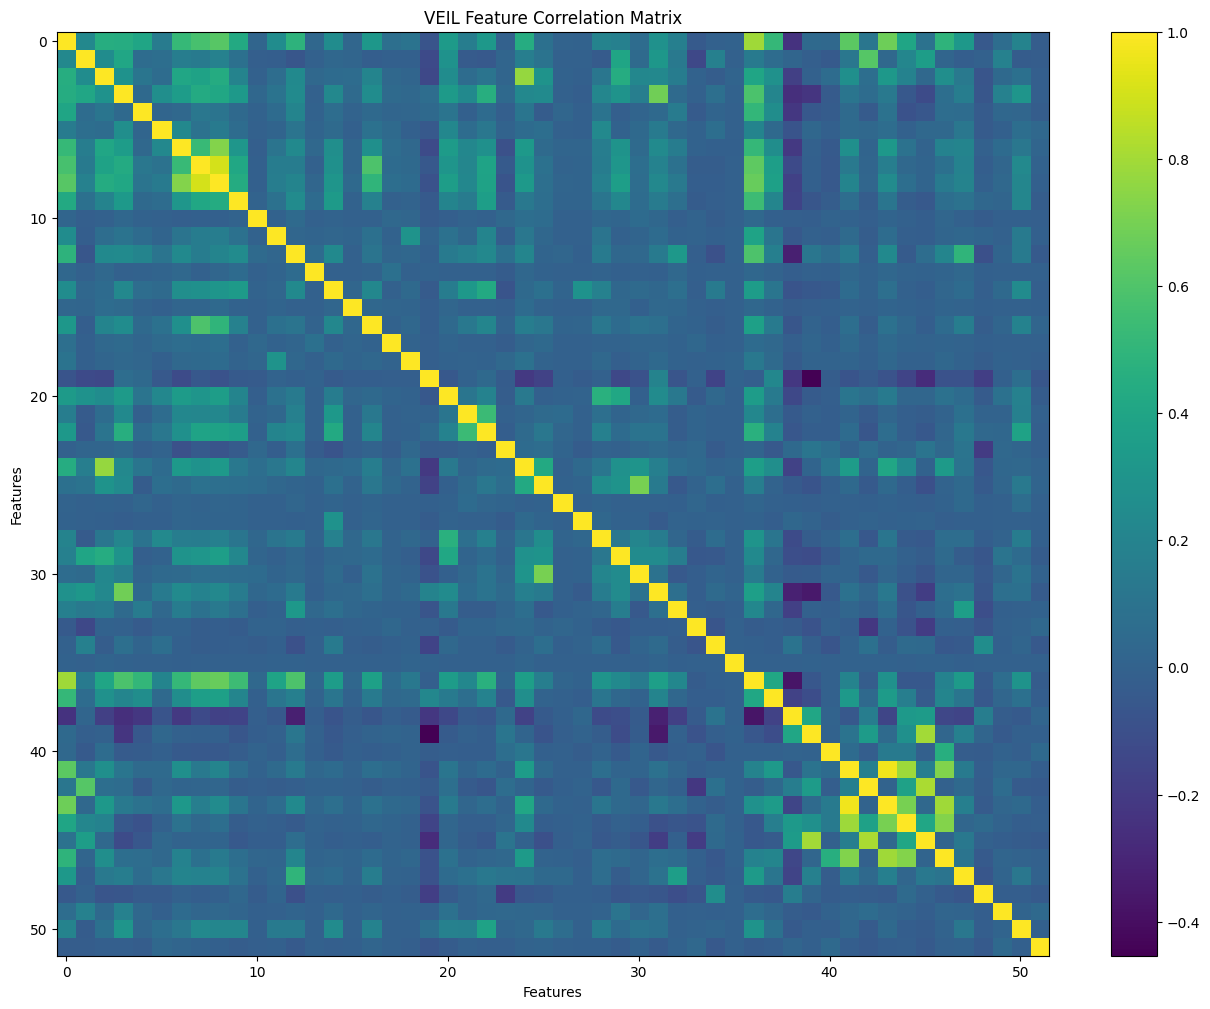

In [41]:
correlation_matrix = X.corr()

plt.figure(figsize=(16, 12))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar()

plt.title("VEIL Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")

plt.show()

In [42]:
feature_variance = X.var().sort_values()

print("LOWEST VARIANCE FEATURES")
print("=" * 60)

print(feature_variance.head(10))

LOWEST VARIANCE FEATURES
path_extension        0.000175
punycode              0.000350
nb_star               0.000700
port                  0.002357
brand_in_subdomain    0.004096
brand_in_path         0.004876
nb_dollar             0.005947
nb_dslash             0.006520
nb_tilde              0.006606
ratio_digits_url      0.007986
dtype: float64


In [43]:
label_mapping = {
    "legitimate": 0,
    "phishing": 1
}

y_encoded = y.map(label_mapping)

print("TARGET ENCODING")
print("=" * 50)
print(y_encoded.value_counts())

TARGET ENCODING
status
0    5715
1    5714
Name: count, dtype: int64


## Train-Test Split

Train-test split is a technique used to divide the dataset into two parts.

- Training Data (80%): Used to train the Machine Learning model.
- Testing Data (20%): Used to evaluate the model's performance on unseen data.

In this project, we used an 80:20 split with stratified sampling to maintain the class distribution in both datasets.

The random_state parameter is set to 42 to ensure reproducible results.

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("DATA SPLIT")
print("=" * 50)
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training labels  :", y_train.shape)
print("Testing labels   :", y_test.shape)

DATA SPLIT
Training features: (9143, 52)
Testing features : (2286, 52)
Training labels  : (9143,)
Testing labels   : (2286,)


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("Logistic Regression ready.")

Logistic Regression ready.


In [46]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [47]:
y_pred = logistic_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 2286


## Model Accuracy – Logistic Regression

The Logistic Regression model achieved an accuracy of 84.56% on the test dataset.

The test dataset contains 2,286 URL samples. Out of these, the model correctly classified 1,933 URLs and incorrectly classified 353 URLs.

This result provides an initial baseline for the VEIL phishing URL detection project.

## Confusion Matrix Interpretation

The confusion matrix shows that the model correctly identified 1,000 legitimate URLs and 933 phishing URLs.

However, 143 legitimate URLs were incorrectly classified as phishing, while 210 phishing URLs were incorrectly classified as legitimate.

This indicates that the model performs reasonably well, but there is still scope for improvement, particularly in detecting phishing URLs.

In [48]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("VEIL - LOGISTIC REGRESSION")
print("=" * 50)
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

VEIL - LOGISTIC REGRESSION
Accuracy: 0.8456
Accuracy: 84.56%


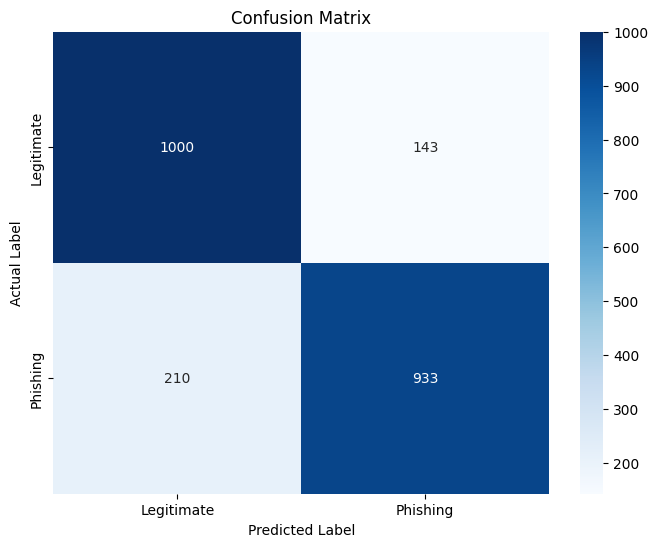

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

### R² Score Evaluation

R² (R-Squared) is a statistical measure used to evaluate how well a regression model explains the variation in the target values.

A higher R² score indicates a better fit for a regression model. However, since VEIL uses Random Forest Classification, R² score is not an appropriate evaluation metric for this model.

In [50]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))

R2 Score: 0.3823
